# TP4 — Détection des Valeurs Aberrantes et Data Skewness

Corrigé des questions 1 à 13. Chaque méthode est appliquée aux observations originales disponibles, sans supprimer les anomalies ni imputer Age. Les détections univariées utilisent 714 âges et 891 tarifs ; la forêt jointe utilise les 714 lignes complètes pour Age et Fare. Une valeur signalée n’est pas nécessairement erronée.

Source : [Titanic, Data Science Dojo](https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv). Le fichier local est chargé en priorité. Les noms de colonnes du CSV sont conservés. Chaque traitement repart des données originales.

In [ ]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import zscore
import missingno as msno
from sklearn.linear_model import LinearRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import IsolationForest
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.dpi': 110})
pd.set_option('display.max_rows', 100)
URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
chemin = Path('titanic.csv')
df_original = pd.read_csv(chemin if chemin.exists() else URL)
df = df_original.copy(deep=True)
def bilan(avant, apres, colonnes=('Age',)):
    display(pd.DataFrame({'Avant': avant[list(colonnes)].isna().sum(),
                          'Après': apres[list(colonnes)].isna().sum()}))
def interpretation(texte):
    display(Markdown('**Interprétation des résultats calculés.** ' + texte))


## Question 1

In [ ]:
display(df[["Age","Fare"]].describe())

,Age,Fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200


### Interprétation

Les échelles diffèrent : Age atteint 80 ans et Fare environ 512,33. Ces maxima doivent être replacés dans leur contexte plutôt que supprimés automatiquement.

## Question 2

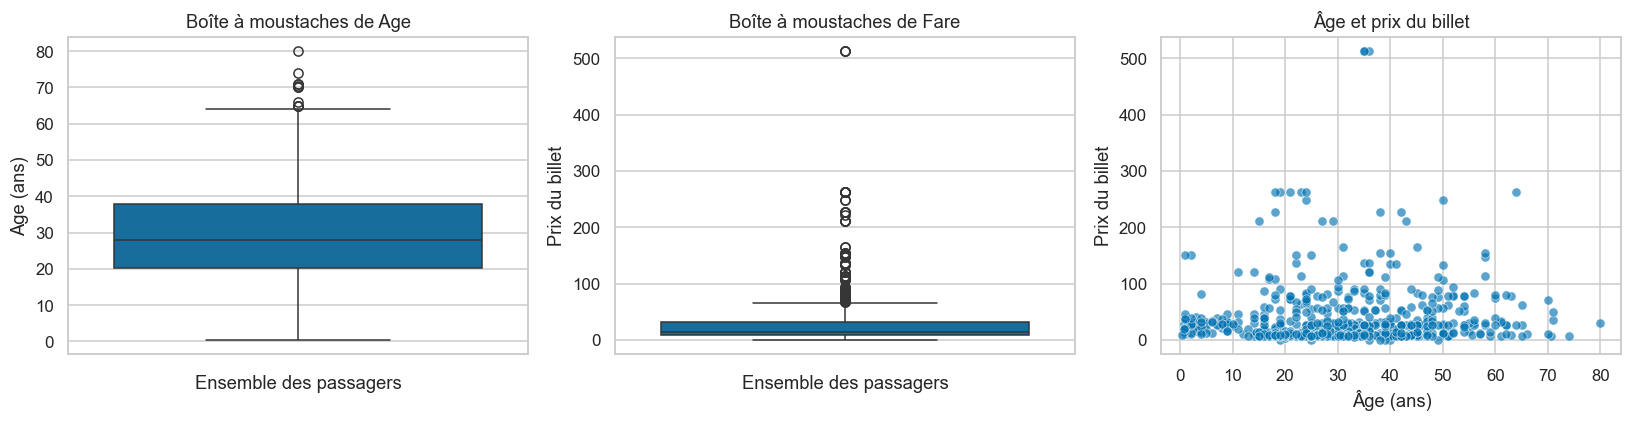

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes[:2],["Age","Fare"]):
    sns.boxplot(y=df[col],ax=ax)
    ax.set(title=f"Boîte à moustaches de {col}",xlabel="Ensemble des passagers",ylabel=f"{col} (ans)" if col=="Age" else "Prix du billet")
sns.scatterplot(data=df,x="Age",y="Fare",ax=axes[2],alpha=.65)
axes[2].set(title="Âge et prix du billet",xlabel="Âge (ans)",ylabel="Prix du billet")
plt.tight_layout(); plt.show()

### Interprétation

Fare présente une longue extension vers les grandes valeurs et de nombreux points au-dessus des moustaches. Quelques âges élevés sont également signalés ; les critères visuels n’établissent pas une erreur.

## Question 3


Age : 2 valeurs aberrantes (|z| > 3)


,PassengerId,Age,Z_score
630,631,80.0,3.465126
851,852,74.0,3.051798


Fare : 20 valeurs aberrantes (|z| > 3)


,PassengerId,Fare,Z_score
27,28,263.0000,4.647001
88,89,263.0000,4.647001
118,119,247.5208,4.335332
258,259,512.3292,9.667167
299,300,247.5208,4.335332
311,312,262.3750,4.634417
341,342,263.0000,4.647001
377,378,211.5000,3.610065
380,381,227.5250,3.932723
438,439,263.0000,4.647001


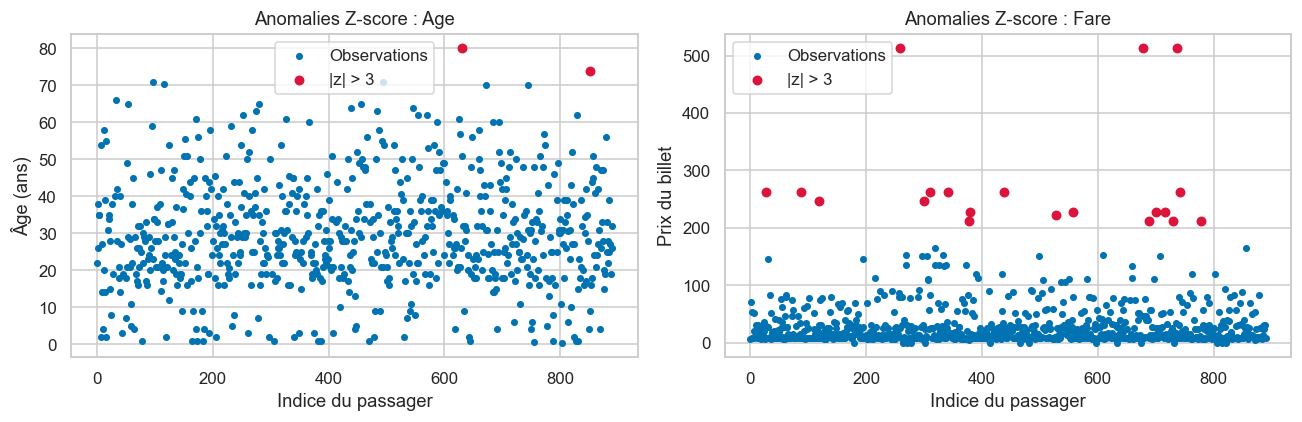

In [ ]:
masques_z = {}
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axes,["Age","Fare"]):
    scores = pd.Series(zscore(df[col],nan_policy="omit",ddof=0),index=df.index)
    masque = scores.abs().gt(3)
    masques_z[col] = masque
    print(f"{col} : {masque.sum()} valeurs aberrantes (|z| > 3)")
    display(df.loc[masque,["PassengerId",col]].assign(Z_score=scores[masque]))
    ax.scatter(df.index,df[col],s=13,label="Observations")
    ax.scatter(df.index[masque],df.loc[masque,col],s=30,color="crimson",label="|z| > 3")
    ax.set(title=f"Anomalies Z-score : {col}",xlabel="Indice du passager",ylabel="Âge (ans)" if col=="Age" else "Prix du billet")
    ax.legend()
plt.tight_layout(); plt.show()

### Interprétation

Le seuil sélectionne des observations très éloignées de la moyenne. Les effectifs et toutes les lignes signalées sont affichés ci-dessus ; la forte asymétrie de Fare limite l’interprétation probabiliste du seuil de trois écarts-types.

## Question 4

In [ ]:
print("Observations utilisables pour le modèle conjoint :", len(df[["Age","Fare"]].dropna()))

Observations utilisables pour le modèle conjoint : 714


### Interprétation

Le modèle conjoint peut utiliser 714 passagers ; 177 lignes sans âge sont exclues uniquement de cette détection.

## Question 5

Age : 32 anomalies univariées sur 714 observations


,PassengerId,Age
33,34,66.00
50,51,7.00
54,55,65.00
58,59,5.00
78,79,0.83
96,97,71.00
116,117,70.50
233,234,5.00
275,276,63.00
278,279,7.00


Fare : 42 anomalies univariées sur 891 observations


,PassengerId,Fare
27,28,263.0000
31,32,146.5208
88,89,263.0000
118,119,247.5208
195,196,146.5208
258,259,512.3292
268,269,153.4625
269,270,135.6333
297,298,151.5500
299,300,247.5208


Anomalies conjointes :

 36


,PassengerId,Age,Fare
27,28,19.00,263.0000
54,55,65.00,61.9792
88,89,23.00,263.0000
96,97,71.00,34.6542
116,117,70.50,7.7500
118,119,24.00,247.5208
195,196,58.00,146.5208
258,259,35.00,512.3292
268,269,58.00,153.4625
297,298,2.00,151.5500


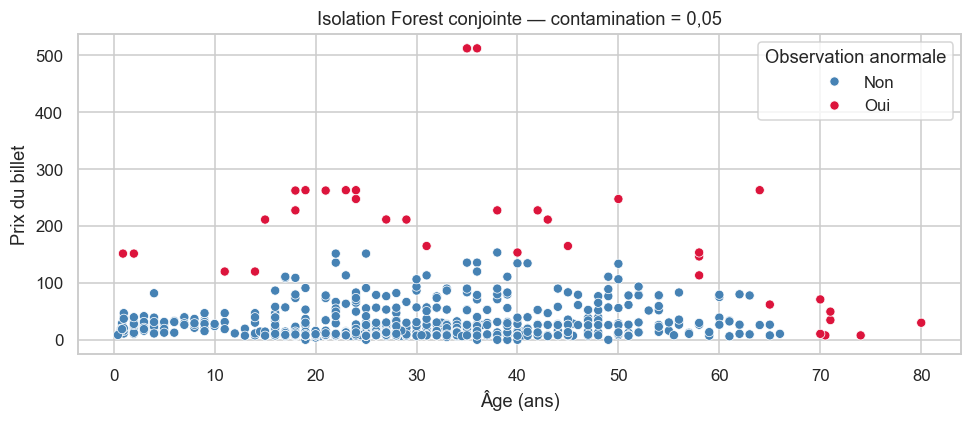

In [ ]:
masques_if = {}
for col in ["Age","Fare"]:
    disponibles = df[[col]].dropna()
    modele = IsolationForest(contamination=0.05,random_state=42)
    etiquettes = modele.fit_predict(disponibles)
    indices = disponibles.index[etiquettes == -1]
    masques_if[col] = df.index.isin(indices)
    print(f"{col} : {len(indices)} anomalies univariées sur {len(disponibles)} observations")
    display(df.loc[indices,["PassengerId",col]])
complets = df[["Age","Fare"]].dropna().copy()
foret = IsolationForest(contamination=0.05,random_state=42)
complets["Anomalie"] = foret.fit_predict(complets) == -1
print("Anomalies conjointes :", complets.Anomalie.sum())
display(df.loc[complets.index[complets.Anomalie],["PassengerId","Age","Fare"]])
sns.scatterplot(data=complets,x="Age",y="Fare",hue=complets["Anomalie"].map({False:"Non",True:"Oui"}),palette={"Non":"steelblue","Oui":"crimson"})
plt.title("Isolation Forest conjointe — contamination = 0,05")
plt.xlabel("Âge (ans)"); plt.ylabel("Prix du billet")
plt.legend(title="Observation anormale"); plt.tight_layout(); plt.show()

### Interprétation

Les détections séparées et conjointes répondent à des questions différentes. Le nombre signalé est piloté par la contamination ; des valeurs identiques peuvent modifier l’effectif exact au seuil. Aucun passager n’est supprimé.

## Question 6 — Comment est calculé l’IQR ?

### Réponse / Explication

Q1 est le 25e percentile et Q3 le 75e. IQR=Q3−Q1. Les bornes de Tukey sont Q1−1,5 IQR et Q3+1,5 IQR ; une valeur strictement extérieure est signalée. Pandas utilise ici une interpolation linéaire des quantiles.

### Code Python

Le code suivant réalise le traitement demandé.

### Résultat

Les sorties exécutées (tableaux, valeurs ou graphiques) figurent directement sous le code.

In [ ]:
lignes_iqr = []
masques_iqr = {}
for col in ["Age","Fare"]:
    q1,q3 = df[col].quantile([.25,.75])
    iqr = q3-q1
    bas,haut = q1-1.5*iqr,q3+1.5*iqr
    masque = (df[col]<bas)|(df[col]>haut)
    masques_iqr[col] = masque
    lignes_iqr.append({"Variable":col,"Q1":q1,"Q3":q3,"IQR":iqr,"Borne inférieure":bas,"Borne supérieure":haut,"Nombre":int(masque.sum())})
table_iqr = pd.DataFrame(lignes_iqr).set_index("Variable")
display(table_iqr)

,Q1,Q3,IQR,Borne inférieure,Borne supérieure,Nombre
Variable,,,,,,
Age,20.1250,38.0,17.8750,-6.6875,64.8125,11
Fare,7.9104,31.0,23.0896,-26.7240,65.6344,116


### Interprétation

Les bornes sont calculées séparément sur les valeurs observées de chaque variable. Une borne négative d’âge est une conséquence de la règle statistique, pas une possibilité biologique.

## Question 7

In [ ]:
display(table_iqr[["Nombre"]])
for col in ["Age","Fare"]:
    print(f"Liste complète des anomalies IQR pour {col}")
    display(df.loc[masques_iqr[col],["PassengerId",col]])
display(pd.DataFrame({"Z-score":{c:int(v.sum()) for c,v in masques_z.items()},"Isolation Forest univariée":{c:int(v.sum()) for c,v in masques_if.items()},"IQR":table_iqr.Nombre}))

,Nombre
Variable,
Age,11
Fare,116


Liste complète des anomalies IQR pour Age


,PassengerId,Age
33,34,66.0
54,55,65.0
96,97,71.0
116,117,70.5
280,281,65.0
456,457,65.0
493,494,71.0
630,631,80.0
672,673,70.0
745,746,70.0


Liste complète des anomalies IQR pour Fare


,PassengerId,Fare
1,2,71.2833
27,28,263.0000
31,32,146.5208
34,35,82.1708
52,53,76.7292
...,...,...
846,847,69.5500
849,850,89.1042
856,857,164.8667
863,864,69.5500


,Z-score,Isolation Forest univariée,IQR
Age,2,32,11
Fare,20,42,116


### Interprétation

IQR détecte 11 âges et 116 tarifs. Les méthodes ne donnent pas les mêmes effectifs car leurs définitions d’une anomalie diffèrent ; aucune ne fournit à elle seule une vérité de référence.

## Question 8

In [ ]:
asymetrie = df[["Age","Fare"]].skew()
display(asymetrie.to_frame("Skewness"))

,Skewness
Age,0.389108
Fare,4.787317


### Interprétation

Age est légèrement asymétrique à droite (environ 0,389), tandis que Fare l’est fortement (environ 4,787).

## Question 9

,Age,Fare
Moyenne,29.699118,32.204208
Médiane,28.000000,14.454200
Skewness,0.389108,4.787317


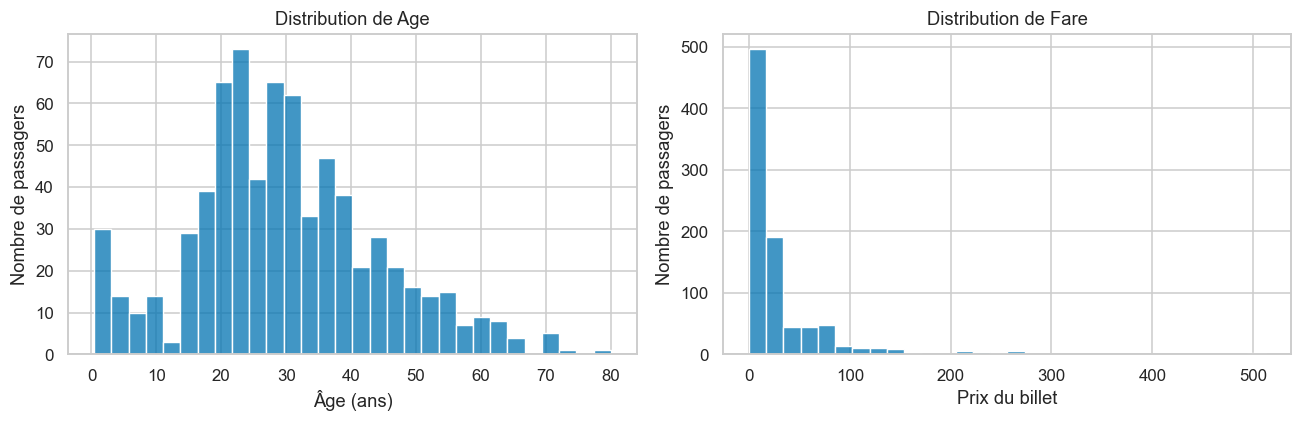

In [ ]:
display(df[["Age","Fare"]].agg(["mean","median","skew"]).rename(index={"mean":"Moyenne","median":"Médiane","skew":"Skewness"}))
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axes,["Age","Fare"]):
    sns.histplot(df[col].dropna(),bins=30,ax=ax)
    ax.set(title=f"Distribution de {col}",xlabel="Âge (ans)" if col=="Age" else "Prix du billet",ylabel="Nombre de passagers")
plt.tight_layout(); plt.show()

### Interprétation

Pour Fare, la moyenne (32,20) dépasse nettement la médiane (14,45), ce qui concorde avec la longue queue droite et le coefficient positif.

## Question 10

In [ ]:
display(df.groupby("Pclass")["Fare"].agg(["count","median","mean","max"]).rename(columns={"count":"Effectif","median":"Médiane","mean":"Moyenne","max":"Maximum"}))

,Effectif,Médiane,Moyenne,Maximum
Pclass,,,,
1,216,60.2875,84.154687,512.3292
2,184,14.2500,20.662183,73.5000
3,491,8.0500,13.675550,69.5500


### Interprétation

La moyenne des tarifs diffère fortement selon la classe. L’hétérogénéité des groupes et les tarifs élevés contribuent à l’asymétrie globale.

## Question 11

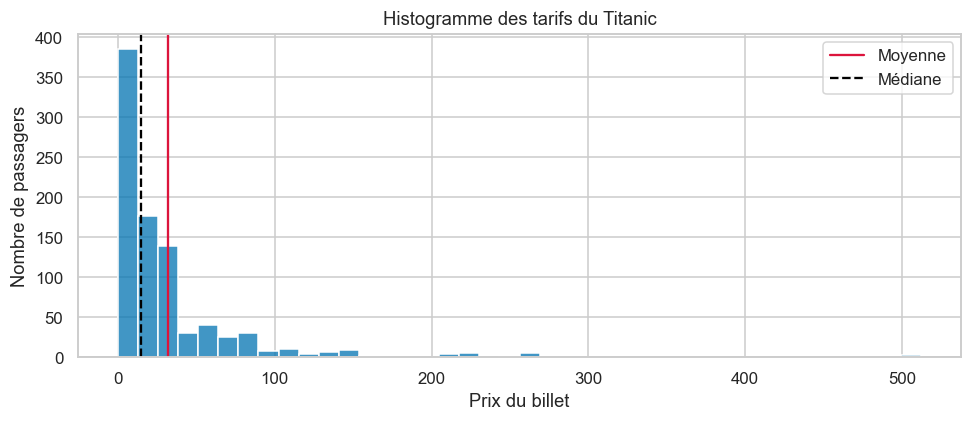

In [ ]:
sns.histplot(df.Fare,bins=40)
plt.axvline(df.Fare.mean(),color="crimson",label="Moyenne")
plt.axvline(df.Fare.median(),color="black",linestyle="--",label="Médiane")
plt.title("Histogramme des tarifs du Titanic")
plt.xlabel("Prix du billet"); plt.ylabel("Nombre de passagers")
plt.legend(); plt.tight_layout(); plt.show()

### Interprétation

La distribution est asymétrique à droite : les fortes valeurs sont rares mais s’étendent très loin du groupe des petits tarifs.

## Question 12

In [ ]:
display(pd.Series({"Fare (queue droite)": df.Fare.skew(),"Opposé de Fare (queue gauche)": (-df.Fare).skew()},name="Skewness"))

Fare (queue droite)              4.787317
Opposé de Fare (queue gauche)   -4.787317
Name: Skewness, dtype: float64

### Interprétation

Changer le signe de Fare inverse exactement le signe de sa skewness. L’opposé de Fare sert uniquement d’illustration mathématique et ne représente pas un prix réel.

## Question 13

Nombre de tarifs nuls : 15


Avant : Fare            4.787317
Après : ln(1 + Fare)    0.394928
Name: Skewness, dtype: float64

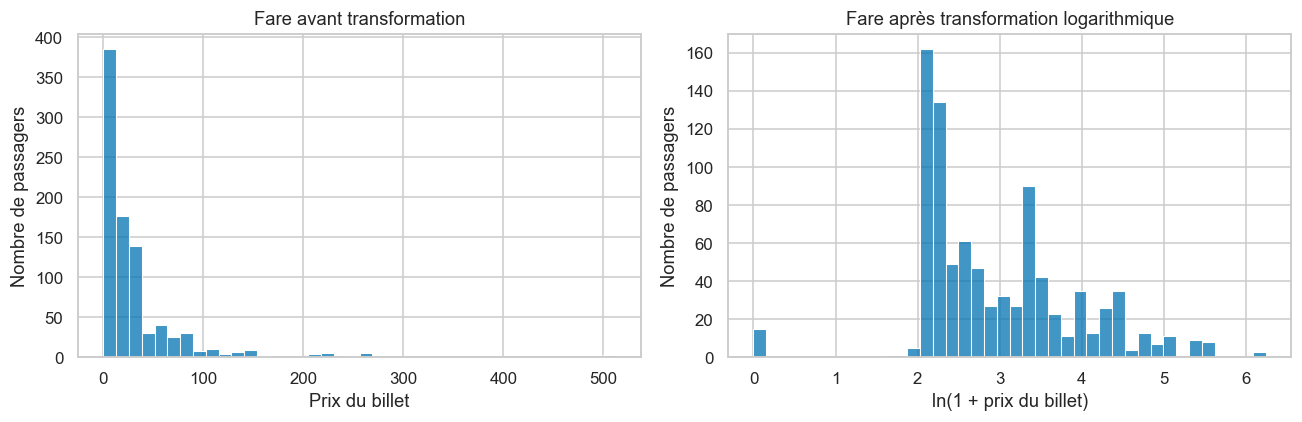

**Interprétation des résultats calculés.** La skewness passe de 4.7873 à 0.3949. Les 15 tarifs nuls restent définis et deviennent 0.

In [ ]:
df_log = df.copy()
assert (df.Fare>=0).all()
df_log["Fare_log"] = np.log1p(df.Fare)
print("Nombre de tarifs nuls :", int(df.Fare.eq(0).sum()))
display(pd.Series({"Avant : Fare":df.Fare.skew(),"Après : ln(1 + Fare)":df_log.Fare_log.skew()},name="Skewness"))
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(df.Fare,bins=40,ax=axes[0])
axes[0].set(title="Fare avant transformation",xlabel="Prix du billet",ylabel="Nombre de passagers")
sns.histplot(df_log.Fare_log,bins=40,ax=axes[1])
axes[1].set(title="Fare après transformation logarithmique",xlabel="ln(1 + prix du billet)",ylabel="Nombre de passagers")
plt.tight_layout(); plt.show()
interpretation(f"La skewness passe de {df.Fare.skew():.4f} à {df_log.Fare_log.skew():.4f}. Les {df.Fare.eq(0).sum()} tarifs nuls restent définis et deviennent 0.")
pd.testing.assert_frame_equal(df,df_original)

### Interprétation

L’asymétrie positive est fortement réduite ; la distribution devient plus équilibrée mais conserve une structure qui n’est pas nécessairement gaussienne. La colonne transformée est ajoutée dans une copie et les tarifs d’origine sont préservés.